# 04 · Modelos: backtest em tempo real (h = 0–4 semanas) e avaliação de H1–H3

Origem rolante semanal; em cada origem $o$, os modelos só veem a versão dos dados conhecida ao fim da semana $o$ (reconstruída pelo triângulo de atraso); as últimas 27 semanas são corrigidas pelo nowcast probabilístico `gamma_rw` (03, §6.1). A semana da origem ($d = 0$) não entra como dado (pior em $h = 0$ e $h \ge 1$ quando entra; §11.1): os modelos preveem $h = 0..4$ a partir de $o - 1$, NB e LightGBM partindo de cada amostra do nowcast de $o - 1$; o `nowcast` de $o$ entra como membro do ensemble em $h = 0$. `lgbm_taxa`: LightGBM com atributos em taxa por 100 mil e offset log(pop) (população do SINASC). Alvo: `vsr` final (corte atual), critério residência, `00-23m`. Código em `vsr_modelos.py`; método em `docs/METODOLOGIA.md` §11.

- **Validação:** alvos nas temporadas 2024 e 2025. **Teste fora de distribuição:** 2026 (imunização).
- **Métricas:** WIS em escala log (principal; Bosse et al., 2023) e natural; WIS relativo ao naive sazonal com IC 95% por bootstrap de origens; cobertura de 50% e 90%.
- **Saídas:** `data/processed/previsoes_backtest.parquet` (23 quantis por modelo × unidade × origem × h) e `avaliacao_backtest.parquet` (escores).

In [1]:
import logging
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import vsr_modelos as vm
from vsr_comum import P, carregar_painel, metadados, verificar_ambiente

verificar_ambiente()
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s", stream=sys.stdout, force=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

META = metadados()
PAINEL = carregar_painel()
TIERS = pd.read_csv(P / "tiers_uf.csv").set_index("unidade")["tier"]
br = PAINEL.loc[PAINEL["unidade"] == "BR"].set_index("semana")
ULTIMO_ALVO = br.index[~br["semana_incompleta"]].max()          # alvos ainda incompletos não são avaliados
ORIGENS = list(pd.date_range("2023-12-31", ULTIMO_ALVO - pd.Timedelta(weeks=max(vm.HORIZONTES)), freq="7D"))
print(f"{len(ORIGENS)} origens: {ORIGENS[0].date()} a {ORIGENS[-1].date()}; último alvo {ULTIMO_ALVO.date()}")

137 origens: 2023-12-31 a 2026-08-09; último alvo 2026-09-06


## 1. Backtest

In [2]:
t0 = time.time()
PREV = vm.backtest(ORIGENS)
PREV.to_parquet(P / f"previsoes_backtest{vm.sufixo()}.parquet", index=False)
print(f"{len(PREV):,} previsões em {time.time() - t0:.0f} s")

2026-10-20 01:32:52,669 INFO origem 2023-12-31 (1/137)


2026-10-20 01:33:21,839 INFO origem 2024-03-10 (11/137)


2026-10-20 01:33:52,880 INFO origem 2024-05-19 (21/137)


2026-10-20 01:34:26,085 INFO origem 2024-07-28 (31/137)


2026-10-20 01:35:02,164 INFO origem 2024-10-06 (41/137)


...

2026-10-20 01:38:24,022 INFO origem 2025-11-30 (101/137)


2026-10-20 01:38:58,090 INFO origem 2026-02-08 (111/137)


2026-10-20 01:39:31,810 INFO origem 2026-04-19 (121/137)


2026-10-20 01:40:05,104 INFO origem 2026-06-28 (131/137)


238,791 previsões em 456 s


In [3]:
obs = PAINEL[["unidade", "semana", vm.SERIE]].rename(columns={vm.SERIE: "vsr"})
SC = vm.pontuar(PREV, obs)
cal = PAINEL.loc[PAINEL["unidade"] == "BR", ["semana", "temporada"]].rename(columns={"semana": "alvo"})
SC = SC.merge(cal, on="alvo", how="left")
SC = SC.loc[(SC["alvo"] <= ULTIMO_ALVO) & SC["temporada"].isin([2024, 2025, 2026])]
SC["periodo"] = np.where(SC["temporada"] == 2026, "teste_2026", "validacao")
SC["tier"] = SC["unidade"].map(TIERS).fillna("agregado")
SC.to_parquet(P / f"avaliacao_backtest{vm.sufixo()}.parquet", index=False)
SC.groupby(["periodo", "nivel"]).size().unstack()

nivel,BRASIL,REGIAO,UF
periodo,,,
teste_2026,2072,10360,46764
validacao,6285,31425,141885


## 2. H1: modelos contra benchmarks (h = 1–4)

WIS relativo ao naive sazonal (< 1 = melhor), no conjunto comum de alvos de cada nível. ETS e ARIMA-Fourier só existem em região e Brasil.

In [4]:
h14 = SC.loc[SC["h"] >= 1]
REL = vm.wis_relativo(h14, por=["periodo", "nivel"])
tab = REL.pivot_table(index="modelo", columns=["periodo", "nivel"], values="wis_rel").round(2)
display(tab.sort_values(("validacao", "UF")))
ic = REL.assign(ic=lambda d: d["wis_rel"].round(2).astype(str) + " [" + d["ic_inf"].round(2).astype(str)
                + ", " + d["ic_sup"].round(2).astype(str) + "]")
display(ic.pivot_table(index="modelo", columns=["periodo", "nivel"], values="ic", aggfunc="first"))

periodo           teste_2026              validacao             
nivel                 BRASIL REGIAO    UF    BRASIL REGIAO    UF
modelo                                                          
lgbm_global             0.52   0.41  0.49      0.61   0.57  0.59
lgbm_taxa               0.53   0.39  0.48      0.61   0.57  0.60
ensemble                0.49   0.45  0.60      0.55   0.55  0.70
nb_mint                 0.51   0.62  0.64      0.81   0.75  0.73
nb_mint_conj            0.48   0.58  0.64      0.69   0.71  0.73
nb_bottom_up_conj       0.42   0.57  0.58      0.67   0.77  0.75
nb_local                0.53   0.45  0.58      0.74   0.66  0.75
nb_bottom_up            0.42   0.58  0.58      0.71   0.78  0.75
naive_sazonal           1.00   1.00  1.00      1.00   1.00  1.00
climatologia            1.48   1.18  1.02      1.55   1.36  1.15
arima_fourier           0.57   0.47   NaN      0.77   0.67   NaN
ets                     1.08   0.68   NaN      0.81   0.77   NaN

periodo                   teste_2026                                                validacao                                      
nivel                         BRASIL             REGIAO                 UF             BRASIL             REGIAO                 UF
modelo                                                                                                                             
arima_fourier       0.57 [0.4, 0.81]  0.47 [0.41, 0.53]                NaN  0.77 [0.66, 0.91]  0.67 [0.62, 0.72]                NaN
climatologia       1.48 [1.06, 2.15]  1.18 [1.08, 1.29]  1.02 [0.98, 1.06]  1.55 [1.37, 1.73]  1.36 [1.25, 1.49]  1.15 [1.09, 1.21]
ensemble            0.49 [0.42, 0.6]  0.45 [0.41, 0.49]   0.6 [0.58, 0.63]  0.55 [0.49, 0.62]  0.55 [0.52, 0.58]   0.7 [0.69, 0.72]
ets                1.08 [0.75, 1.53]  0.68 [0.61, 0.74]                NaN   0.81 [0.68, 1.0]  0.77 [0.68, 0.87]                NaN
lgbm_global          0.52 [0.4, 0.7]  0.41 [0.36, 0.46]  0.49 [0.47, 0.52]  0.61 [0.51, 0.73]  0.57 [0.52, 0.62]  0.59 [0.56, 0.62]
lgbm_taxa           0.53 [0.4, 0.71]  0.39 [0.35, 0.44]  0.48 [0.45, 0.51]  0.61 [0.52, 0.71]  0.57 [0.52, 0.63]   0.6 [0.56, 0.63]
naive_sazonal         1.0 [1.0, 1.0]     1.0 [1.0, 1.0]     1.0 [1.0, 1.0]     1.0 [1.0, 1.0]     1.0 [1.0, 1.0]     1.0 [1.0, 1.0]
nb_bottom_up       0.42 [0.32, 0.55]   0.58 [0.5, 0.67]  0.58 [0.54, 0.63]   0.71 [0.6, 0.83]  0.78 [0.73, 0.82]  0.75 [0.72, 0.78]
nb_bottom_up_conj  0.42 [0.33, 0.56]  0.57 [0.48, 0.65]  0.58 [0.54, 0.63]  0.67 [0.58, 0.78]  0.77 [0.72, 0.81]  0.75 [0.72, 0.78]
nb_local            0.53 [0.4, 0.72]   0.45 [0.4, 0.52]  0.58 [0.54, 0.63]  0.74 [0.63, 0.87]  0.66 [0.61, 0.71]  0.75 [0.72, 0.78]
nb_mint             0.51 [0.37, 0.7]  0.62 [0.52, 0.71]   0.64 [0.59, 0.7]   0.81 [0.7, 0.95]    0.75 [0.7, 0.8]   0.73 [0.7, 0.75]
nb_mint_conj       0.48 [0.36, 0.66]   0.58 [0.5, 0.67]   0.64 [0.59, 0.7]   0.69 [0.6, 0.81]  0.71 [0.66, 0.75]   0.73 [0.7, 0.76]

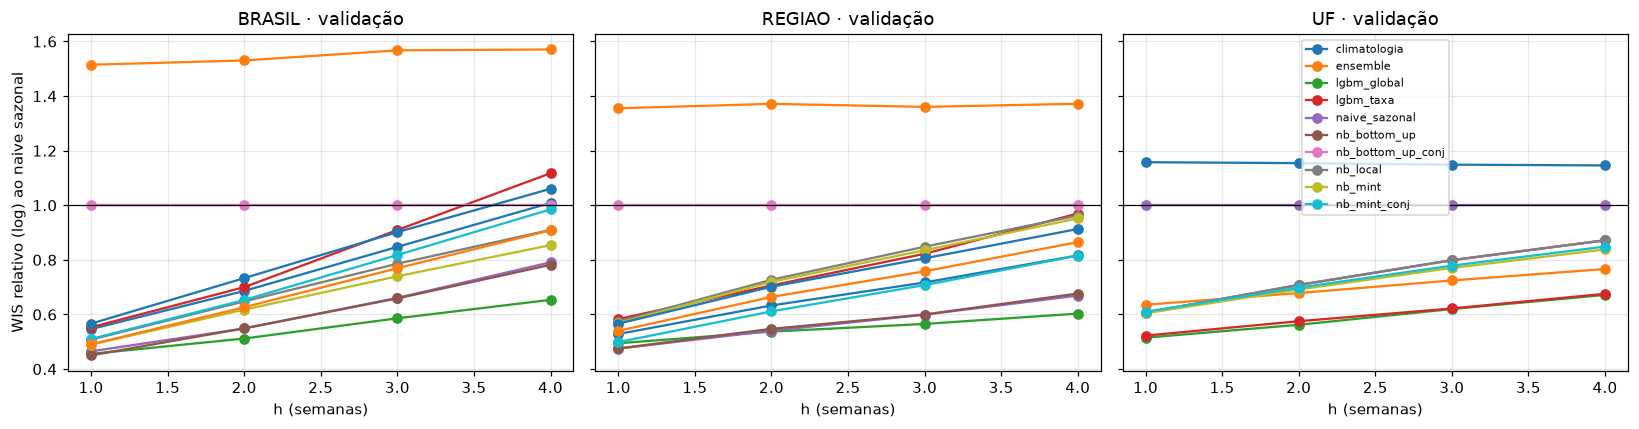

In [5]:
por_h = vm.wis_relativo(h14.loc[h14["periodo"] == "validacao"], por=["nivel", "h"])
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (nv, g) in zip(axs, por_h.groupby("nivel")):
    for m, gm in g.groupby("modelo"):
        ax.plot(gm["h"], gm["wis_rel"], marker="o", label=m)
    ax.axhline(1, color="k", lw=0.8); ax.set_title(f"{nv} · validação"); ax.set_xlabel("h (semanas)")
axs[0].set_ylabel("WIS relativo (log) ao naive sazonal"); axs[-1].legend(fontsize=7)
fig.tight_layout()

## 3. Calibração: cobertura dos intervalos de 50% e 90%

In [6]:
cob = h14.groupby(["periodo", "nivel", "modelo"])[["cob50", "cob90"]].mean().round(2).unstack(["periodo", "nivel"])
display(cob)

cob50                                          cob90                                    
periodo           teste_2026              validacao              teste_2026              validacao             
nivel                 BRASIL REGIAO    UF    BRASIL REGIAO    UF     BRASIL REGIAO    UF    BRASIL REGIAO    UF
modelo                                                                                                         
arima_fourier           0.54   0.52   NaN      0.21   0.31   NaN       0.83   0.86   NaN      0.65   0.74   NaN
climatologia            0.52   0.30  0.37      0.47   0.34  0.42       1.00   0.80  0.76      0.77   0.71  0.69
ensemble                0.85   0.70  0.49      0.56   0.56  0.48       1.00   0.96  0.89      0.97   0.94  0.85
ets                     0.51   0.49   NaN      0.44   0.43   NaN       0.79   0.86   NaN      0.79   0.83   NaN
lgbm_global             0.30   0.37  0.52      0.37   0.42  0.64       0.82   0.81  0.85      0.78   0.82  0.88
lgbm_taxa               0.36   0.41  0.53      0.35   0.39  0.61       0.86   0.85  0.86      0.76   0.81  0.86
naive_sazonal           0.59   0.45  0.39      0.55   0.46  0.48       0.97   0.82  0.83      0.85   0.86  0.83
nb_bottom_up            0.40   0.33  0.51      0.22   0.29  0.52       0.82   0.67  0.85      0.50   0.59  0.78
nb_bottom_up_conj       0.48   0.32  0.51      0.24   0.28  0.52       0.93   0.74  0.85      0.64   0.67  0.78
nb_local                0.49   0.43  0.51      0.23   0.36  0.52       0.91   0.84  0.85      0.71   0.72  0.78
nb_mint                 0.30   0.26  0.44      0.14   0.25  0.39       0.65   0.63  0.84      0.32   0.53  0.76
nb_mint_conj            0.41   0.30  0.38      0.22   0.28  0.34       0.91   0.76  0.83      0.68   0.67  0.73

## 4. H2: estratégias hierárquicas

Estratégias com a mesma família de modelo base (NB harmônica): `nb_local` (cada unidade ajustada sozinha), `nb_bottom_up` (soma das amostras das UFs), `nb_mint` (MinT-shrink sobre amostras de todas as unidades) e `lgbm_global` (modelo global nas UFs + bottom-up). Versões `_conj`: amostras conjuntas entre unidades e horizontes por Schaake shuffle com o molde dos resíduos do NB (`vm.schaake`); `lgbm_global` já é conjunto. Nas UFs, `nb_bottom_up` = `nb_local` (marginais idênticas). Para UFs, o recorte por tier testa o ganho onde há poucos casos.

In [7]:
ESTR = ["nb_local", "nb_bottom_up", "nb_mint", "nb_bottom_up_conj", "nb_mint_conj", "lgbm_global", "lgbm_taxa"]
e = h14.loc[h14["modelo"].isin(ESTR)]
H2 = vm.wis_relativo(e, por=["periodo", "nivel"], base="nb_local")
display(H2.pivot_table(index="modelo", columns=["periodo", "nivel"], values="wis_rel").round(3))
H2T = vm.wis_relativo(e.loc[e["nivel"] == "UF"], por=["periodo", "tier"], base="nb_local")
display(H2T.pivot_table(index="modelo", columns=["periodo", "tier"], values="wis_rel").round(3))
print("cobertura nos agregados (h = 1–4): independentes × conjuntas")
display(e.loc[e["nivel"] != "UF"].groupby(["nivel", "modelo"])[["cob50", "cob90"]].mean().round(2).unstack(0))

periodo           teste_2026               validacao              
nivel                 BRASIL REGIAO     UF    BRASIL REGIAO     UF
modelo                                                            
lgbm_global            0.986  0.902  0.845     0.832  0.868  0.794
lgbm_taxa              0.995  0.869  0.827     0.824  0.874  0.803
nb_bottom_up           0.791  1.285  1.000     0.962  1.182  1.000
nb_bottom_up_conj      0.795  1.251  1.000     0.911  1.168  1.000
nb_local               1.000  1.000  1.000     1.000  1.000  1.000
nb_mint                0.957  1.357  1.102     1.100  1.134  0.973
nb_mint_conj           0.912  1.284  1.101     0.943  1.074  0.984

periodo           teste_2026               validacao              
tier                       A      B      C         A      B      C
modelo                                                            
lgbm_global            0.839  0.866  0.830     0.836  0.755  0.709
lgbm_taxa              0.849  0.824  0.778     0.841  0.768  0.725
nb_bottom_up           1.000  1.000  1.000     1.000  1.000  1.000
nb_bottom_up_conj      1.000  1.000  1.000     1.000  1.000  1.000
nb_local               1.000  1.000  1.000     1.000  1.000  1.000
nb_mint                1.175  1.058  0.990     0.994  0.956  0.929
nb_mint_conj           1.156  1.063  1.021     0.995  0.975  0.957

cobertura nos agregados (h = 1–4): independentes × conjuntas


cob50         cob90       
nivel             BRASIL REGIAO BRASIL REGIAO
modelo                                       
lgbm_global         0.36   0.41   0.79   0.82
lgbm_taxa           0.35   0.40   0.79   0.82
nb_bottom_up        0.26   0.30   0.58   0.61
nb_bottom_up_conj   0.30   0.29   0.72   0.69
nb_local            0.30   0.38   0.76   0.75
nb_mint             0.18   0.25   0.40   0.55
nb_mint_conj        0.26   0.28   0.73   0.69

## 5. H3: robustez do ensemble em 2026

Ensemble = média dos quantis de `naive_sazonal`, `climatologia`, `nb_local`, `lgbm_global` e, em região e Brasil, `ets` e `arima_fourier`. H3 reformulada: o ensemble perde menos que os modelos individuais na passagem da validação para 2026 (primeira temporada com imunização)?

In [8]:
pos = REL.pivot_table(index="modelo", columns=["nivel", "periodo"], values="wis_rel")
for nv in ("BRASIL", "REGIAO", "UF"):
    pos[(nv, "razao_2026_valid")] = pos[(nv, "teste_2026")] / pos[(nv, "validacao")]
display(pos.sort_index(axis=1).round(2))
rank = REL.assign(posto=REL.groupby(["periodo", "nivel"])["wis_rel"].rank())
display(rank.pivot_table(index="modelo", columns=["nivel", "periodo"], values="posto"))

nivel                       BRASIL                                REGIAO                                    UF                     
periodo           razao_2026_valid teste_2026 validacao razao_2026_valid teste_2026 validacao razao_2026_valid teste_2026 validacao
modelo                                                                                                                             
arima_fourier                 0.74       0.57      0.77             0.70       0.47      0.67              NaN        NaN       NaN
climatologia                  0.96       1.48      1.55             0.87       1.18      1.36             0.88       1.02      1.15
ensemble                      0.89       0.49      0.55             0.82       0.45      0.55             0.86       0.60      0.70
ets                           1.33       1.08      0.81             0.88       0.68      0.77              NaN        NaN       NaN
lgbm_global                   0.85       0.52      0.61             0.72       0.41      0.57             0.83       0.49      0.59
lgbm_taxa                     0.87       0.53      0.61             0.69       0.39      0.57             0.80       0.48      0.60
naive_sazonal                 1.00       1.00      1.00             1.00       1.00      1.00             1.00       1.00      1.00
nb_bottom_up                  0.59       0.42      0.71             0.75       0.58      0.78             0.78       0.58      0.75
nb_bottom_up_conj             0.63       0.42      0.67             0.74       0.57      0.77             0.78       0.58      0.75
nb_local                      0.72       0.53      0.74             0.69       0.45      0.66             0.78       0.58      0.75
nb_mint                       0.62       0.51      0.81             0.83       0.62      0.75             0.88       0.64      0.73
nb_mint_conj                  0.70       0.48      0.69             0.83       0.58      0.71             0.87       0.64      0.73

nivel                 BRASIL               REGIAO                   UF          
periodo           teste_2026 validacao teste_2026 validacao teste_2026 validacao
modelo                                                                          
arima_fourier            9.0       8.0        5.0       5.0        NaN       NaN
climatologia            12.0      12.0       12.0      12.0       10.0      10.0
ensemble                 4.0       1.0        3.0       1.0        6.0       3.0
ets                     11.0      10.0       10.0       9.0        NaN       NaN
lgbm_global              6.0       3.0        2.0       2.0        2.0       1.0
lgbm_taxa                7.0       2.0        1.0       3.0        1.0       2.0
naive_sazonal           10.0      11.0       11.0      11.0        9.0       9.0
nb_bottom_up             1.0       6.0        8.0      10.0        4.0       7.0
nb_bottom_up_conj        2.0       4.0        6.0       8.0        4.0       7.0
nb_local                 8.0       7.0        4.0       4.0        4.0       7.0
nb_mint                  5.0       9.0        9.0       7.0        8.0       4.0
nb_mint_conj             3.0       5.0        7.0       6.0        7.0       5.0

## 6. Semana da origem (h = 0): modelos a partir de o − 1, `nowcast` de o e ensemble

In [9]:
h0 = vm.wis_relativo(SC.loc[SC["h"] == 0], por=["periodo", "nivel"])
display(h0.pivot_table(index="modelo", columns=["periodo", "nivel"], values="wis_rel").round(2))
display(SC.loc[SC["h"] == 0].groupby(["periodo", "nivel", "modelo"])[["wis_log", "cob90"]].mean().round(3)
        .unstack(["periodo", "nivel"]).loc[["nowcast", "ensemble", "lgbm_global", "nb_local"]])

periodo           teste_2026              validacao             
nivel                 BRASIL REGIAO    UF    BRASIL REGIAO    UF
modelo                                                          
arima_fourier           0.38   0.32   NaN      0.40   0.43   NaN
climatologia            1.37   1.23  1.06      1.52   1.35  1.17
ensemble                0.39   0.36  0.49      0.38   0.43  0.54
ets                     0.46   0.37   NaN      0.41   0.46   NaN
lgbm_global             0.35   0.28  0.40      0.37   0.40  0.47
lgbm_taxa               0.36   0.29  0.40      0.36   0.40  0.48
naive_sazonal           1.00   1.00  1.00      1.00   1.00  1.00
nb_bottom_up            0.32   0.28  0.42      0.35   0.42  0.50
nb_bottom_up_conj       0.32   0.28  0.42      0.34   0.42  0.50
nb_local                0.36   0.29  0.42      0.37   0.40  0.50
nb_mint                 0.35   0.31  0.44      0.40   0.43  0.51
nb_mint_conj            0.34   0.31  0.44      0.35   0.41  0.52
nowcast                 0.50   0.38  0.45      0.48   0.47  0.54

wis_log                                            cob90                                      
periodo     teste_2026               validacao               teste_2026               validacao              
nivel           BRASIL REGIAO     UF    BRASIL REGIAO     UF     BRASIL REGIAO     UF    BRASIL REGIAO     UF
modelo                                                                                                       
nowcast          0.137  0.198  0.276     0.176  0.238  0.280      1.000  0.962  0.904     0.962  0.930  0.893
ensemble         0.106  0.185  0.301     0.138  0.219  0.281      1.000  0.988  0.919     0.990  0.954  0.899
lgbm_global      0.096  0.145  0.246     0.135  0.201  0.244      0.812  0.869  0.866     0.838  0.861  0.899
nb_local         0.099  0.150  0.259     0.135  0.204  0.261      0.969  0.906  0.889     0.886  0.884  0.873

## 7. Previsões em exemplo (h = 2): Brasil, regiões e uma UF por tier

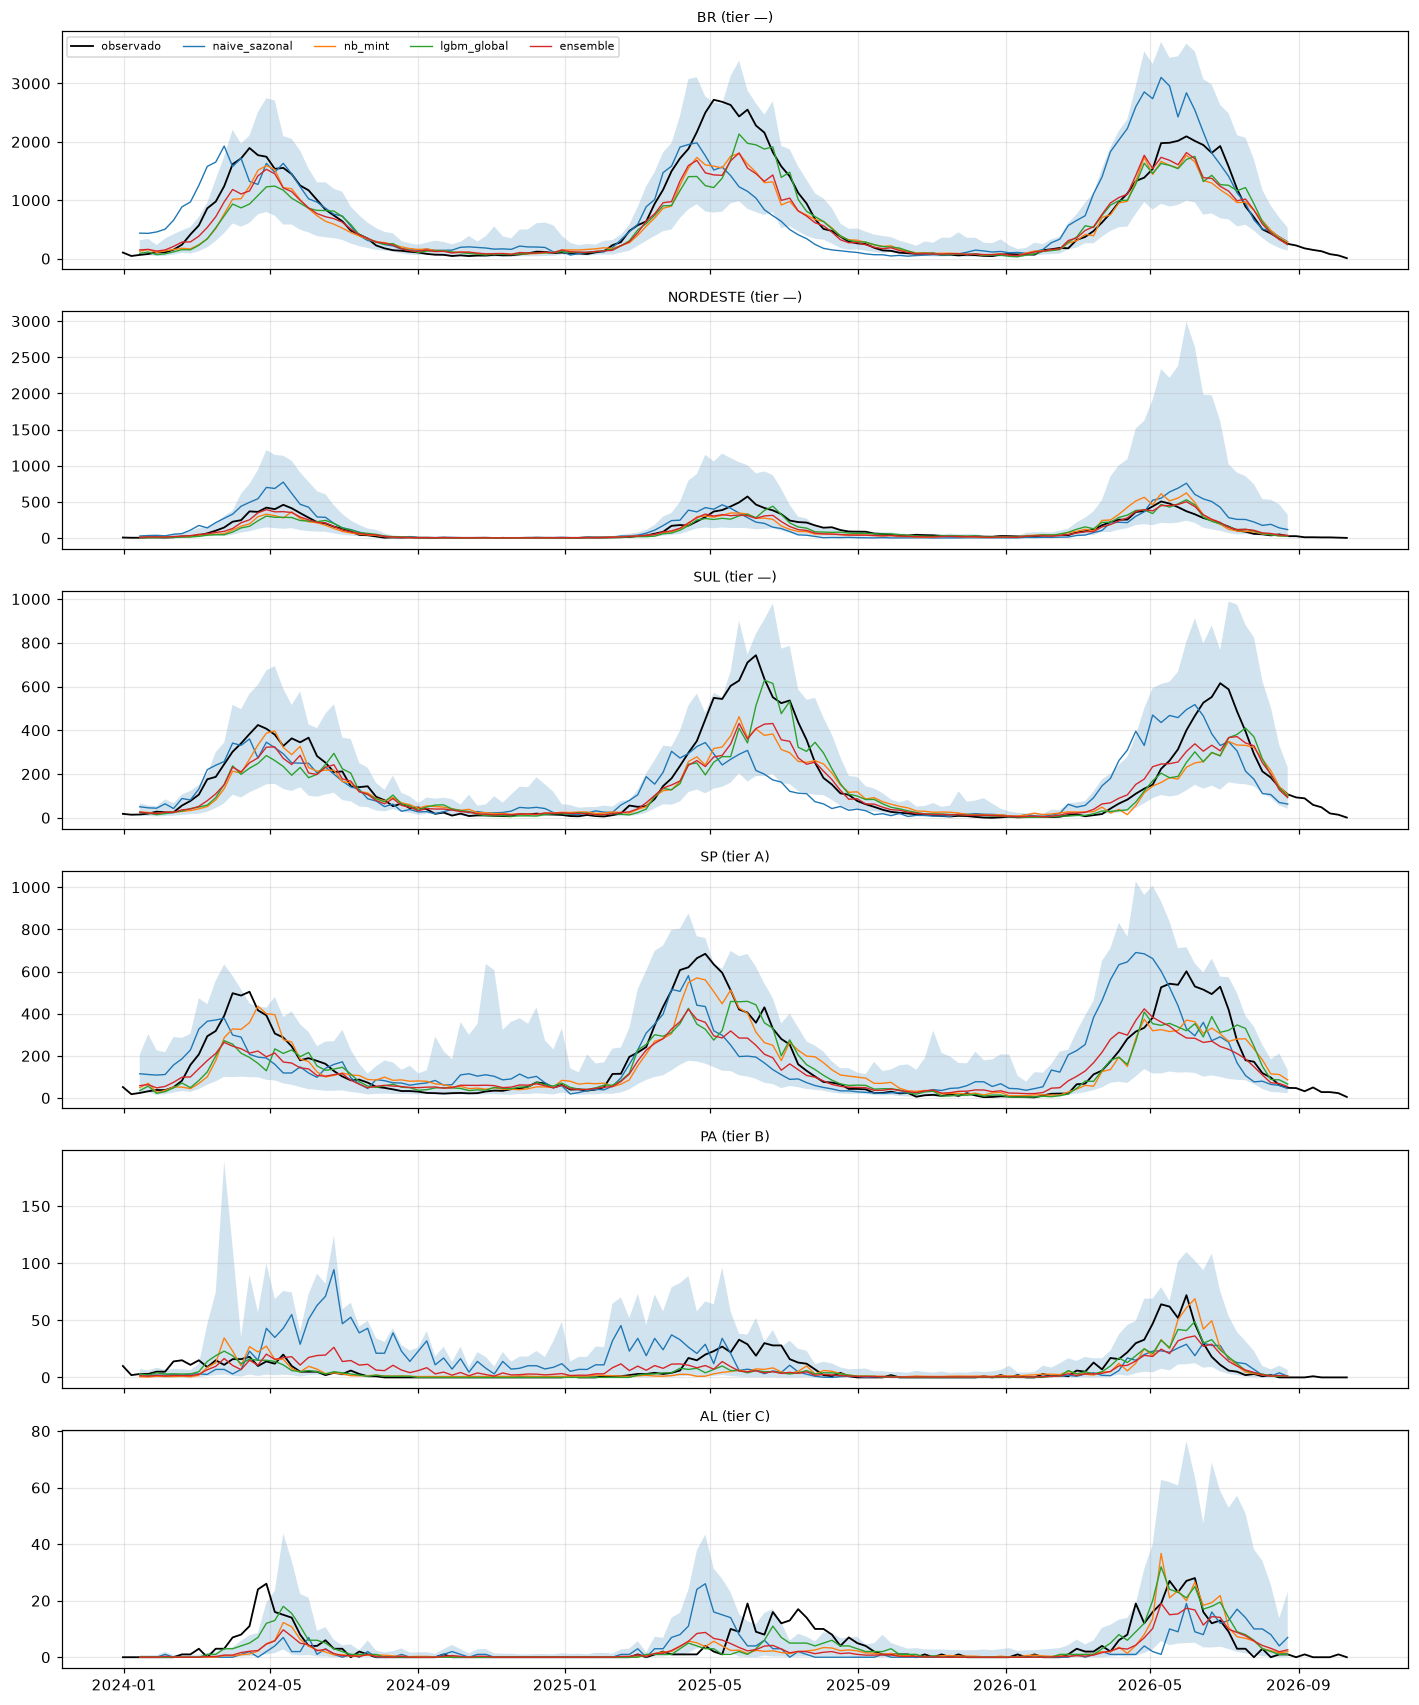

In [10]:
EX = ["BR", "NORDESTE", "SUL", "SP", "PA", "AL"]
mods = ["naive_sazonal", "nb_mint", "lgbm_global", "ensemble"]
fig, axs = plt.subplots(len(EX), 1, figsize=(13, 2.6 * len(EX)), sharex=True)
for ax, u in zip(axs, EX):
    o = PAINEL.loc[(PAINEL["unidade"] == u) & (PAINEL["semana"] >= ORIGENS[0])]
    ax.plot(o["semana"], o[vm.SERIE], color="k", lw=1.2, label="observado")
    for m in mods:
        p = PREV.loc[(PREV["unidade"] == u) & (PREV["modelo"] == m) & (PREV["h"] == 2)].sort_values("alvo")
        ax.plot(p["alvo"], p["q0.5"], lw=0.9, label=m)
        if m == "ensemble":
            ax.fill_between(p["alvo"], p["q0.05"], p["q0.95"], alpha=0.2)
    ax.set_title(f"{u} (tier {TIERS.get(u, '—')})", fontsize=9)
axs[0].legend(fontsize=7, ncol=5); fig.tight_layout()

## 8. Resumo

In [11]:
v = REL.loc[REL["periodo"] == "validacao"].pivot_table(index="modelo", columns="nivel", values="wis_rel")
t = REL.loc[REL["periodo"] == "teste_2026"].pivot_table(index="modelo", columns="nivel", values="wis_rel")
print("melhor modelo por nível (validação):", v.idxmin().to_dict())
print("melhor modelo por nível (2026):", t.idxmin().to_dict())
print("ensemble, WIS relativo validação/2026:", v.loc["ensemble"].round(2).to_dict(), t.loc["ensemble"].round(2).to_dict())
print("H2 (UF, validação), relativo a nb_local:", H2.query("periodo == 'validacao' and nivel == 'UF'")
      .set_index("modelo")["wis_rel"].round(3).to_dict())

melhor modelo por nível (validação): {'BRASIL': 'ensemble', 'REGIAO': 'ensemble', 'UF': 'lgbm_global'}
melhor modelo por nível (2026): {'BRASIL': 'nb_bottom_up', 'REGIAO': 'lgbm_taxa', 'UF': 'lgbm_taxa'}
ensemble, WIS relativo validação/2026: {'BRASIL': 0.55, 'REGIAO': 0.55, 'UF': 0.7} {'BRASIL': 0.49, 'REGIAO': 0.45, 'UF': 0.6}
H2 (UF, validação), relativo a nb_local: {'nb_local': 1.0, 'nb_bottom_up': 1.0, 'nb_mint': 0.973, 'nb_bottom_up_conj': 1.0, 'nb_mint_conj': 0.984, 'lgbm_global': 0.794, 'lgbm_taxa': 0.803}
